# AdventureWorks – Advanced Data Analytics

## 1. Présentation du projet

Ce projet consiste à analyser les données commerciales
d'AdventureWorks à l'aide de Python.

L'objectif est d'étudier les performances des ventes,
le comportement des clients, la rentabilité des produits
et les tendances commerciales.

## 2. Objectifs

- Explorer et comprendre les données.
- Évaluer leur qualité.
- Réaliser des analyses statistiques et commerciales.
- Identifier des opportunités d'amélioration.
- Produire des recommandations métier.

In [1]:
# Manipulation et analyse des données
import pandas as pd
import numpy as np

# Visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# Configuration
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

sns.set_theme(style="whitegrid")

plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["figure.dpi"] = 100

print("Environnement d'analyse initialisé.")

Environnement d'analyse initialisé.


In [4]:
from pathlib import Path

# Définition du chemin du fichier
BASE_DIR = Path.cwd().parent
DATA_PATH = BASE_DIR / "data" / "raw" / "AdventureWorks_Database.xlsx"

# Chargement des feuilles Excel
donnees = pd.read_excel(DATA_PATH, sheet_name=None)

# Attribution des noms aux tables
dim_date = donnees["Sheet2"]
dim_customer = donnees["Sheet3"]
dim_product = donnees["Sheet4"]
fact_sales = donnees["Sheet5"]
dim_territory = donnees["Sheet6"]

print("Chargement terminé.")

Chargement terminé.


## 3. Exploration de la structure des données

Cette section permet d'examiner les dimensions, les colonnes,
les types de variables et la structure générale des différentes tables.

In [7]:
# Dictionnaire des tables
tables = {
    "DimDate": dim_date,
    "DimCustomer": dim_customer,
    "DimProduct": dim_product,
    "FactInternetSales": fact_sales,
    "DimSalesTerritory": dim_territory
}

# Affichage des dimensions des tables
for nom, df in tables.items():
    print(f"\n{'=' * 50}")
    print(f"TABLE : {nom}")
    print(f"{'=' * 50}")
    print(f"Nombre de lignes : {df.shape[0]:,}")
    print(f"Nombre de colonnes : {df.shape[1]}")


TABLE : DimDate
Nombre de lignes : 1,461
Nombre de colonnes : 16

TABLE : DimCustomer
Nombre de lignes : 18,484
Nombre de colonnes : 17

TABLE : DimProduct
Nombre de lignes : 606
Nombre de colonnes : 13

TABLE : FactInternetSales
Nombre de lignes : 58,189
Nombre de colonnes : 13

TABLE : DimSalesTerritory
Nombre de lignes : 11
Nombre de colonnes : 5


In [9]:
# Structure détaillée des tables
for nom, df in tables.items():
    print(f"\n{'=' * 60}")
    print(f"STRUCTURE DE LA TABLE : {nom}")
    print(f"{'=' * 60}")

    df.info()


STRUCTURE DE LA TABLE : DimDate
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1461 entries, 0 to 1460
Data columns (total 16 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Date            1461 non-null   datetime64[ns]
 1   DateKey         1461 non-null   int64         
 2   Year            1461 non-null   int64         
 3   Quarter         1461 non-null   object        
 4   MonthNum        1461 non-null   int64         
 5   Month           1461 non-null   object        
 6   FiscalYear      1461 non-null   object        
 7   FiscalQuarter   1461 non-null   object        
 8   FiscalMonthNum  1461 non-null   int64         
 9   FiscalMonth     1461 non-null   object        
 10  MonthYear       1461 non-null   object        
 11  MonthYearLong   1461 non-null   object        
 12  MonthYearNum    1461 non-null   int64         
 13  WeekdayNum      1461 non-null   int64         
 14  Weekday         1461 no

In [13]:
# Création d'un inventaire des variables
inventaire = []

for nom, df in tables.items():
    for colonne in df.columns:
        inventaire.append({
            "Table": nom,
            "Variable": colonne,
            "Type": str(df[colonne].dtype),
            "Valeurs_non_nulles": df[colonne].count(),
            "Valeurs_manquantes": df[colonne].isna().sum(),
            "Valeurs_uniques": df[colonne].nunique()
        })

inventaire_variables = pd.DataFrame(inventaire)

display(inventaire_variables)

,Table,Variable,Type,Valeurs_non_nulles,Valeurs_manquantes,Valeurs_uniques
0,DimDate,Date,datetime64[ns],1461,0,1461
1,DimDate,DateKey,int64,1461,0,1461
2,DimDate,Year,int64,1461,0,4
3,DimDate,Quarter,object,1461,0,4
4,DimDate,MonthNum,int64,1461,0,12
5,DimDate,Month,object,1461,0,12
6,DimDate,FiscalYear,object,1461,0,5
7,DimDate,FiscalQuarter,object,1461,0,4
8,DimDate,FiscalMonthNum,int64,1461,0,12
9,DimDate,FiscalMonth,object,1461,0,12


In [68]:
# Affichage des colonnes de chaque table
for nom, df in tables.items():
    print(f"\n{nom}")
    print(df.columns.tolist())


DimDate
['Date', 'DateKey', 'Year', 'Quarter', 'MonthNum', 'Month', 'FiscalYear', 'FiscalQuarter', 'FiscalMonthNum', 'FiscalMonth', 'MonthYear', 'MonthYearLong', 'MonthYearNum', 'WeekdayNum', 'Weekday', 'WeekdayWeekend']

DimCustomer
['CustomerKey', 'FirstName', 'LastName', 'FullName', 'BirthDate', 'MaritalStatus', 'Gender', 'YearlyIncome', 'TotalChildren', 'NumberChildrenAtHome', 'Education', 'Occupation', 'HouseOwnerFlag', 'NumberCarsOwned', 'AddressLine1', 'DateFirstPurchase', 'CommuteDistance']

DimProduct
['ProductKey', 'ProductName', 'SubCategory', 'Category', 'StandardCost', 'Color', 'ListPrice', 'DaysToManufacture', 'ProductLine', 'ModelName', 'Photo', 'ProductDescription', 'StartDate']

FactInternetSales
['ProductKey', 'OrderDate', 'ShipDate', 'CustomerKey', 'PromotionKey', 'SalesTerritoryKey', 'SalesOrderNumber', 'SalesOrderLineNumber', 'OrderQuantity', 'UnitPrice', 'TotalProductCost', 'SalesAmount', 'TaxAmt', 'OrderYear', 'ShipYear']

DimSalesTerritory
['SalesTerritoryKey',

## 4. Analyse du modèle relationnel

### 4.1 Vérification des clés primaires

L'objectif est de vérifier que chaque table dimensionnelle
possède une clé primaire unique et qu'aucune valeur de clé
n'est manquante.

In [22]:
# Clés primaires des tables dimensionnelles

cles_primaires = {
    "DimDate": ("DateKey", dim_date),
    "DimCustomer": ("CustomerKey", dim_customer),
    "DimProduct": ("ProductKey", dim_product),
    "DimSalesTerritory": ("SalesTerritoryKey", dim_territory)
}

resultats_cles = []

for nom_table, (colonne, df) in cles_primaires.items():

    resultats_cles.append({
        "Table": nom_table,
        "Clé primaire": colonne,
        "Valeurs totales": len(df),
        "Valeurs uniques": df[colonne].nunique(),
        "Valeurs manquantes": df[colonne].isna().sum(),
        "Doublons": df[colonne].duplicated().sum(),
        "Clé valide": (
            df[colonne].notna().all()
            and df[colonne].is_unique
        )
    })

verification_cles = pd.DataFrame(resultats_cles)

display(verification_cles)

,Table,Clé primaire,Valeurs totales,Valeurs uniques,Valeurs manquantes,Doublons,Clé valide
0,DimDate,DateKey,1461,1461,0,0,True
1,DimCustomer,CustomerKey,18484,18484,0,0,True
2,DimProduct,ProductKey,606,606,0,0,True
3,DimSalesTerritory,SalesTerritoryKey,11,11,0,0,True


In [30]:
# Définition des relations entre les tables

relations = {
    "ProductKey": {
        "table_faits": fact_sales,
        "table_dimension": dim_product
    },
    "CustomerKey": {
        "table_faits": fact_sales,
        "table_dimension": dim_customer
    },
    "SalesTerritoryKey": {
        "table_faits": fact_sales,
        "table_dimension": dim_territory
    }
}

resultats_relations = []

for cle, tables_relation in relations.items():

    faits = tables_relation["table_faits"]
    dimension = tables_relation["table_dimension"]

    valeurs_faits = set(faits[cle].dropna().unique())
    valeurs_dimension = set(dimension[cle].dropna().unique())

    cles_orphelines = valeurs_faits - valeurs_dimension

    resultats_relations.append({
        "Clé étrangère": cle,
        "Références dans les ventes": len(valeurs_faits),
        "Références dans la dimension": len(valeurs_dimension),
        "Clés orphelines": len(cles_orphelines),
        "Intégrité référentielle": (
            "Valide" if len(cles_orphelines) == 0
            else "À vérifier"
        )
    })

verification_relations = pd.DataFrame(resultats_relations)

display(verification_relations)

,Clé étrangère,Références dans les ventes,Références dans la dimension,Clés orphelines,Intégrité référentielle
0,ProductKey,158,606,0,Valide
1,CustomerKey,17918,18484,0,Valide
2,SalesTerritoryKey,10,11,0,Valide


In [32]:
# Analyse de la granularité des ventes

analyse_commandes = {
    "Nombre de lignes de vente": len(fact_sales),

    "Nombre de commandes": (
        fact_sales["SalesOrderNumber"].nunique()
    ),

    "Nombre de clients": (
        fact_sales["CustomerKey"].nunique()
    ),

    "Nombre de produits": (
        fact_sales["ProductKey"].nunique()
    ),

    "Nombre de lignes par commande": (
        fact_sales.groupby("SalesOrderNumber").size().mean()
    )
}

for indicateur, valeur in analyse_commandes.items():
    print(f"{indicateur} : {valeur:,.2f}" if isinstance(valeur, float)
          else f"{indicateur} : {valeur:,}")

Nombre de lignes de vente : 58,189
Nombre de commandes : 26,683
Nombre de clients : 17,918
Nombre de produits : 158
Nombre de lignes par commande : 2.18


In [36]:
# Vérification de l'unicité des lignes de commande

doublons_lignes = fact_sales.duplicated(
    subset=["SalesOrderNumber", "SalesOrderLineNumber"]
).sum()

print("Doublons commande / ligne :", doublons_lignes)

Doublons commande / ligne : 0


In [40]:
# Période couverte par les différentes tables

print("CALENDRIER")
print("Date minimale :", dim_date["Date"].min())
print("Date maximale :", dim_date["Date"].max())

print("\nVENTES")
print("Première commande :", fact_sales["OrderDate"].min())
print("Dernière commande :", fact_sales["OrderDate"].max())

print("\nEXPÉDITIONS")
print("Première expédition :", fact_sales["ShipDate"].min())
print("Dernière expédition :", fact_sales["ShipDate"].max())

CALENDRIER
Date minimale : 2014-01-01 00:00:00
Date maximale : 2017-12-31 00:00:00

VENTES
Première commande : 2014-01-01 00:00:00
Dernière commande : 2016-12-30 00:00:00

EXPÉDITIONS
Première expédition : 2014-01-08 00:00:00
Dernière expédition : 2017-01-07 00:00:00


In [44]:
# Vérification de l'unicité des lignes de commande

doublons_lignes = fact_sales.duplicated(
    subset=["SalesOrderNumber", "SalesOrderLineNumber"]
).sum()

print("Nombre de doublons :", doublons_lignes)

if doublons_lignes == 0:
    print("Chaque ligne de commande possède une combinaison unique.")
else:
    print("Des combinaisons commande / ligne sont dupliquées.")

Nombre de doublons : 0
Chaque ligne de commande possède une combinaison unique.


In [48]:
# Création de l'ensemble des dates du calendrier
dates_calendrier = set(dim_date["Date"].dt.normalize())

# Vérification des dates de commande
dates_commandes = set(
    fact_sales["OrderDate"].dt.normalize()
)

# Vérification des dates d'expédition
dates_expeditions = set(
    fact_sales["ShipDate"].dt.normalize()
)

# Dates absentes du calendrier
commandes_hors_calendrier = dates_commandes - dates_calendrier
expeditions_hors_calendrier = dates_expeditions - dates_calendrier

print("Dates de commande absentes :", len(commandes_hors_calendrier))
print("Dates d'expédition absentes :", len(expeditions_hors_calendrier))

Dates de commande absentes : 0
Dates d'expédition absentes : 0


In [52]:
# Extraction des années
fact_sales["OrderYear"] = fact_sales["OrderDate"].dt.year
fact_sales["ShipYear"] = fact_sales["ShipDate"].dt.year

# Comparaison des volumes annuels
print("Commandes par année :")
display(fact_sales["OrderYear"].value_counts().sort_index())

print("\nExpéditions par année :")
display(fact_sales["ShipYear"].value_counts().sort_index())

Commandes par année :


OrderYear
2014     2206
2015     3222
2016    52761
Name: count, dtype: int64


Expéditions par année :


ShipYear
2014     2159
2015     3198
2016    51546
2017     1286
Name: count, dtype: int64

In [56]:
# Analyse annuelle des ventes

analyse_annuelle = (
    fact_sales
    .groupby(fact_sales["OrderDate"].dt.year)
    .agg(
        Nombre_commandes=("SalesOrderNumber", "nunique"),
        Nombre_lignes=("SalesOrderLineNumber", "count"),
        Chiffre_affaires=("SalesAmount", "sum"),
        Quantites_vendues=("OrderQuantity", "sum"),
        Clients_uniques=("CustomerKey", "nunique")
    )
    .rename_axis("Annee")
    .reset_index()
)

display(analyse_annuelle.round(2))

,Annee,Nombre_commandes,Nombre_lignes,Chiffre_affaires,Quantites_vendues,Clients_uniques
0,2014,2206,2206,7072084.24,3492,2206
1,2015,3222,3222,5762134.30,4945,3222
2,2016,21255,52761,16473618.05,82884,17412


In [60]:
# Calcul du nombre de lignes par commande

lignes_par_commande = (
    fact_sales
    .groupby("SalesOrderNumber")
    .agg(
        Nombre_lignes=("SalesOrderLineNumber", "count"),
        Nombre_clients=("CustomerKey", "nunique"),
        Date_commande=("OrderDate", "first")
    )
    .reset_index()
)

lignes_par_commande["Annee"] = (
    lignes_par_commande["Date_commande"].dt.year
)

# Synthèse annuelle de la structure des commandes

structure_commandes = (
    lignes_par_commande
    .groupby("Annee")
    .agg(
        Nombre_commandes=("SalesOrderNumber", "count"),
        Commandes_une_ligne=(
            "Nombre_lignes",
            lambda x: (x == 1).sum()
        ),
        Commandes_plusieurs_lignes=(
            "Nombre_lignes",
            lambda x: (x > 1).sum()
        ),
        Moyenne_lignes_par_commande=("Nombre_lignes", "mean"),
        Commandes_avec_plusieurs_clients=(
            "Nombre_clients",
            lambda x: (x > 1).sum()
        )
    )
    .reset_index()
)

display(structure_commandes.round(2))

,Annee,Nombre_commandes,Commandes_une_ligne,Commandes_plusieurs_lignes,Moyenne_lignes_par_commande,Commandes_avec_plusieurs_clients
0,2014,2206,2206,0,1.00,0
1,2015,3222,3222,0,1.00,0
2,2016,21255,3997,17258,2.48,0


In [64]:
# Analyse mensuelle des ventes

analyse_mensuelle = (
    fact_sales
    .groupby(fact_sales["OrderDate"].dt.to_period("M"))
    .agg(
        Nombre_commandes=("SalesOrderNumber", "nunique"),
        Nombre_lignes=("SalesOrderLineNumber", "count"),
        Chiffre_affaires=("SalesAmount", "sum"),
        Quantites_vendues=("OrderQuantity", "sum")
    )
    .reset_index()
)

analyse_mensuelle["Mois"] = (
    analyse_mensuelle["OrderDate"].astype(str)
)

display(analyse_mensuelle.drop(columns="OrderDate").round(2))

,Nombre_commandes,Nombre_lignes,Chiffre_affaires,Quantites_vendues,Mois
0,146,146,473388.16,246,2014-01
1,156,156,506191.69,246,2014-02
2,146,146,473943.03,227,2014-03
3,161,161,513329.47,269,2014-04
4,169,169,543993.41,265,2014-05
5,235,235,755527.89,354,2014-06
6,188,188,596746.56,286,2014-07
7,171,171,550816.69,279,2014-08
8,199,199,644135.20,316,2014-09
9,207,207,663692.29,339,2014-10


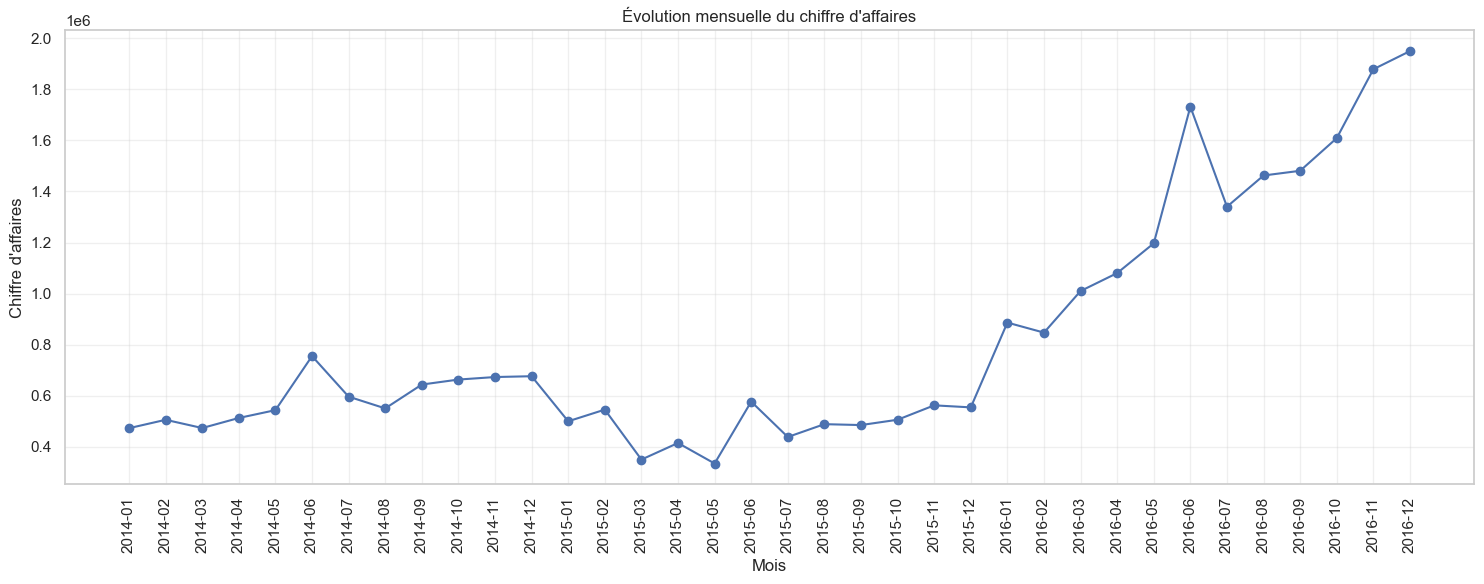

In [70]:
plt.figure(figsize=(15, 6))

plt.plot(
    analyse_mensuelle["Mois"],
    analyse_mensuelle["Chiffre_affaires"],
    marker="o"
)

plt.title("Évolution mensuelle du chiffre d'affaires")
plt.xlabel("Mois")
plt.ylabel("Chiffre d'affaires")
plt.xticks(rotation=90)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Conclusion — Compréhension des données

L'analyse initiale du jeu de données AdventureWorks a permis d'identifier cinq tables principales :

- `DimDate` : 1 461 lignes
- `DimCustomer` : 18 484 lignes
- `DimProduct` : 606 lignes
- `FactInternetSales` : 58 189 lignes
- `DimSalesTerritory` : 11 lignes

Le modèle repose sur une structure en étoile, avec une table centrale de ventes reliée aux dimensions clients, produits, dates et territoires.

### Principaux résultats

- 58 189 lignes de vente et 26 683 commandes distinctes.
- 17 918 clients ayant effectué au moins un achat.
- 158 produits présents dans les ventes.
- Aucune clé étrangère orpheline détectée.
- Aucune combinaison du numéro de commande et du numéro de ligne en doublon.
- Aucune date de commande ou d'expédition absente du calendrier.

### Premières observations métier

L'activité commerciale est fortement concentrée sur l'année 2016, qui représente environ 90,7 % des lignes de vente.

La structure des commandes diffère également selon les années. Les commandes de 2014 et 2015 comportent toutes une seule ligne, tandis que celles de 2016 comportent en moyenne 2,48 lignes.

L'évolution mensuelle du chiffre d'affaires montre une accélération importante en 2016, avec des niveaux particulièrement élevés en juin, novembre et décembre.

### Points à approfondir

- Examiner les valeurs manquantes dans les dimensions clients, produits et territoires.
- Vérifier les éventuelles incohérences de dates et de montants.
- Étudier les produits présents dans le catalogue mais absents des ventes.
- Analyser les distributions statistiques et les valeurs atypiques.
- Préparer un jeu de données fiable pour les analyses commerciales.

**Conclusion :** la structure générale des données et les relations entre les tables sont cohérentes. Une analyse approfondie de la qualité des données reste nécessaire avant de construire les indicateurs et les analyses métier.
